<a href="https://colab.research.google.com/github/AlfCR/dnn-estadia/blob/main/notebooks/LSTM_ENTRENAMIENTO_ACP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Fase 3: Diseño y Entrenamiento de DNN
**Arquitectura: LSTM**

In [ ]:
# Celda 1
from google.colab import drive
drive.mount('/content/drive')

# Clonar el repositorio para traer el archivo modelos.py
!git clone https://github.com/AlfCR/dnn-estadia.git
%cd dnn-estadia
!git pull

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cloning into 'dnn-estadia'...
remote: Enumerating objects: 64, done.
remote: Counting objects: 100% (64/64), done.
remote: Compressing objects: 100% (52/52), done.
remote: Total 64 (delta 19), reused 32 (delta 6), pack-reused 0 (from 0)
Receiving objects: 100% (64/64), 88.89 KiB | 6.84 MiB/s, done.
Resolving deltas: 100% (19/19), done.
/content/dnn-estadia
Already up to date.


In [ ]:
# Celda 2
import sys
import os
sys.path.append('/content/dnn-estadia/src') #Para  importar modelos.py
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from modelos import crear_modelo, obtener_callbacks

# Semilla fija para reproducibilidad
tf.random.set_seed(42) #Semillas usadas: 42 [], 7[], 123[], 2026 [] y 99 []
np.random.seed(42)
print("Librerias y módulo importados")


Librerias y módulo importados


##Cargar el dataset

In [ ]:
# Celda 3
ruta = '/content/drive/MyDrive/Colab Notebooks/dataset/dataset_limpio/dataset_preparado_3d.npz'
datos = np.load(ruta)

X_train = datos['X_train']
y_train = datos['y_train']
X_val = datos['X_val']
y_val = datos['y_val']
X_test = datos['X_test']
y_test = datos['y_test']

print("Datos cargados")
print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape}")
print(f"y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape}")
print(f"y_test:  {y_test.shape}")


Datos cargados
X_train: (6959, 30, 23)
y_train: (6959,)
X_val:   (1343, 30, 23)
y_val:   (1343,)
X_test:  (2342, 30, 23)
y_test:  (2342,)


####Calcular la línea base

In [ ]:
# celda 4
promedio_train = np.mean(y_train)
rmse_base = np.sqrt(np.mean((y_val - promedio_train)**2))

print(f"RMSE Línea Base (Validación): {rmse_base:.4f}")
print("El modelo debe de dar un RMSE menor a esto para ser considerado útil")

RMSE Línea Base (Validación): 0.9795
El modelo debe de dar un RMSE menor a esto para ser considerado útil


In [ ]:
# Celda 5
"""Definir el modelo"""
modelo = crear_modelo('LSTM')
callbacks = obtener_callbacks(paciencia=10)

#Definir el metodo FIT (Para entrenar LSTM)
"""Definimos parametros de entrenamiento"""
EPOCHS = 100
BATCH_SIZE = 64
print('Iniciando el entrenamiento del modelo ...')

modelo.summary()
"""Ejecutar el método fit"""
lstm_history = modelo.fit(X_train, y_train,
                          epochs=EPOCHS,
                          batch_size=BATCH_SIZE,
                          validation_data=(X_val, y_val),
                          callbacks=callbacks,
                          verbose=1)

Iniciando el entrenamiento del modelo ...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        22,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,585 (92.13 KB)

 Trainable params: 23,585 (92.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step - loss: 0.7734 - mae: 0.6707 - val_loss: 0.7063 - val_mae: 0.6192
Epoch 2/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - loss: 0.6022 - mae: 0.5686 - val_loss: 0.6570 - val_mae: 0.5905
Epoch 3/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.5571 - mae: 0.5424 - val_loss: 0.6341 - val_mae: 0.5771
Epoch 4/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.5326 - mae: 0.5273 - val_loss: 0.6207 - val_mae: 0.5677
Epoch 5/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.5151 - mae: 0.5157 - val_loss: 0.6110 - val_mae: 0.5610
Epoch 6/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 0.4897 - mae: 0.5027 - val_loss: 0.6087 - val_mae: 0.5656
Epoch 7/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - loss: 0.4700 - mae: 0.4942 - val_loss: 0.6207 - val_mae: 0.5640
Epoch 8/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.4560 - mae: 0.4901 - val_loss: 0.6035 - val_mae: 0.5663
Epoch 9/100
109/109 ━━━━━━━━━━━━━━━━━━━━

In [ ]:
# Celda 6
import numpy as np

# 1. Evaluar en Prueba (Test)
resultados_test = modelo.evaluate(X_test, y_test, verbose=0)
mse_test = resultados_test[0]
mae_test = resultados_test[1]
rmse_test = np.sqrt(mse_test)

# 2. Evaluar en Validación
resultados_val = modelo.evaluate(X_val, y_val, verbose=0)
mse_val = resultados_val[0]
rmse_val = np.sqrt(mse_val)

# 3. Calcular Líneas base (promedio de train)
promedio_train = np.mean(y_train)
rmse_base_val = np.sqrt(np.mean((y_val - promedio_train)**2))
rmse_base_test = np.sqrt(np.mean((y_test - promedio_train)**2))

# 4. Calcular porcentajes de mejora
mejora_val = ((rmse_base_val - rmse_val) / rmse_base_val) * 100
mejora_test = ((rmse_base_test - rmse_test) / rmse_base_test) * 100

# 5. Imprimir resultados finales
print(' MÉTRICAS FINALES DEL LSTM ')
print(f"Validación (MSE): {mse_val:.4f} | RMSE: {rmse_val:.4f}")
print(f"Prueba (MSE):     {mse_test:.4f} | RMSE: {rmse_test:.4f} | MAE: {mae_test:.4f}")
print(f"Línea base (Validación): {rmse_base_val:.4f} | Mejora: {mejora_val:.2f}%")
print(f"Línea base (Prueba):     {rmse_base_test:.4f} | Mejora: {mejora_test:.2f}%")

 MÉTRICAS FINALES DEL LSTM 
Validación (MSE): 0.5963 | RMSE: 0.7722
Prueba (MSE):     0.7475 | RMSE: 0.8646 | MAE: 0.6159
Línea base (Validación): 0.9795 | Mejora: 21.16%
Línea base (Prueba):     1.0043 | Mejora: 13.91%


In [ ]:
# celda 7
import json
ruta_modelos = '/content/drive/MyDrive/Colab Notebooks/modelos'
os.makedirs(ruta_modelos, exist_ok=True)

# 1. Guardar el modelo entrenado
modelo.save(os.path.join(ruta_modelos, 'modelo_lstm_base.h5'))

# 2. Guardar el historial de entrenamiento
with open(os.path.join(ruta_modelos, 'historia_lstm_base.json'), 'w') as f:
    json.dump(lstm_history.history, f)

print("Modelo y historial guardados en la carpeta 'modelos' de Drive")





Modelo y historial guardados en la carpeta 'modelos' de Drive


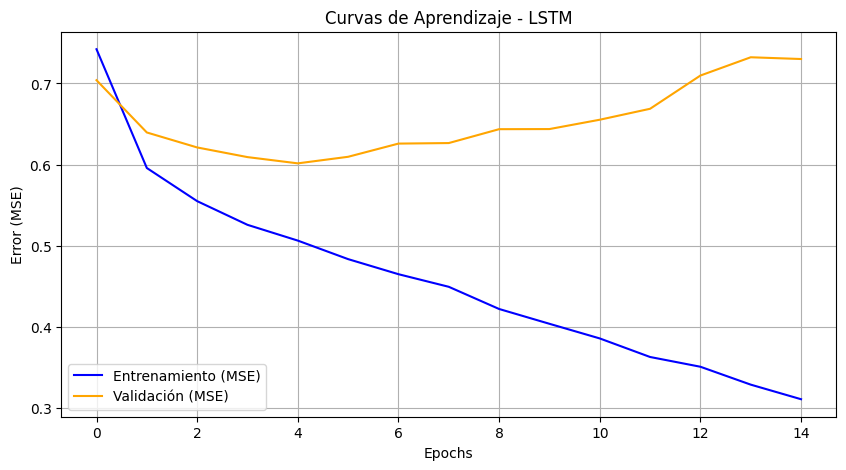

Gráfica guardada exitosamente en: /content/drive/MyDrive/Colab Notebooks/modelos/curvas_lstm.png


In [ ]:
import matplotlib.pyplot as plt
import os

# Crear la gráfica
plt.figure(figsize=(10, 5))
plt.plot(lstm_history.history['loss'], label='Entrenamiento (MSE)', color='blue')
plt.plot(lstm_history.history['val_loss'], label='Validación (MSE)', color='orange')
plt.title('Curvas de Aprendizaje - LSTM')
plt.xlabel('Epochs')
plt.ylabel('Error (MSE)')
plt.legend()
plt.grid(True)

# Guardar la imagen en Drive
ruta_grafica = os.path.join(ruta_modelos, 'curvas_lstm.png')
plt.savefig(ruta_grafica, dpi=300, bbox_inches='tight')

# Mostrarla en pantalla
plt.show()

print(f"Gráfica guardada exitosamente en: {ruta_grafica}")

In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from modelos import crear_modelo, obtener_callbacks
import os

# 1. Definimos las semillas a probar
semillas = [7, 123, 2026, 99]
resultados = []

print("Iniciando entrenamiento automatizado para LSTM...")

for semilla in semillas:
    print(f"\n--- Evaluando con Semilla: {semilla} ---")

    # Fijar la semilla
    tf.random.set_seed(semilla)
    np.random.seed(semilla)

    # Crear y entrenar el modelo
    modelo_temp = crear_modelo(tipo='LSTM')
    callbacks = obtener_callbacks(paciencia=10)

    # Entrenar (verbose=0 para que no llene la pantalla de texto)
    modelo_temp.fit(X_train, y_train,
                    epochs=100,
                    batch_size=64,
                    validation_data=(X_val, y_val),
                    callbacks=callbacks,
                    verbose=0)

    # Evaluar
    res_test = modelo_temp.evaluate(X_test, y_test, verbose=0)
    res_val = modelo_temp.evaluate(X_val, y_val, verbose=0)

    rmse_test = np.sqrt(res_test[0])
    mae_test = res_test[1]
    rmse_val = np.sqrt(res_val[0])

    # Calcular mejora
    promedio_train = np.mean(y_train)
    rmse_base_test = np.sqrt(np.mean((y_test - promedio_train)**2))
    mejora = ((rmse_base_test - rmse_test) / rmse_base_test) * 100

    # Guardar en la lista
    resultados.append({
        'Semilla': semilla,
        'RMSE Val': round(rmse_val, 4),
        'RMSE Test': round(rmse_test, 4),
        'MAE Test': round(mae_test, 4),
        'Mejora (%)': round(mejora, 2)
    })

    # Guardar el modelo en Drive (opcional pero recomendado)
    ruta_modelos = '/content/drive/MyDrive/Colab Notebooks/modelos'
    os.makedirs(ruta_modelos, exist_ok=True)
    modelo_temp.save(os.path.join(ruta_modelos, f'modelo_lstm_seed{semilla}.h5'))

# 2. Crear la tabla final
df_resultados = pd.DataFrame(resultados)

# Agregar fila de promedio
promedios = df_resultados.mean(numeric_only=True).round(4)
promedios['Semilla'] = 'Promedio'
df_resultados = pd.concat([df_resultados, pd.DataFrame([promedios])], ignore_index=True)

print("\n✅ ¡Entrenamiento terminado! Aquí está tu tabla:")
display(df_resultados)

# Guardar la tabla en un CSV para que no la pierdas
df_resultados.to_csv(os.path.join(ruta_modelos, 'resultados_lstm_semillas.csv'), index=False)
print("Tabla guardada como 'resultados_lstm_semillas.csv' en tu Drive.")

Iniciando entrenamiento automatizado para LSTM...

--- Evaluando con Semilla: 7 ---
Epoch 15: early stopping
Restoring model weights from the end of the best epoch: 5.



--- Evaluando con Semilla: 123 ---
Epoch 16: early stopping
Restoring model weights from the end of the best epoch: 6.



--- Evaluando con Semilla: 2026 ---
Epoch 15: early stopping
Restoring model weights from the end of the best epoch: 5.



--- Evaluando con Semilla: 99 ---
Epoch 17: early stopping
Restoring model weights from the end of the best epoch: 7.



✅ ¡Entrenamiento terminado! Aquí está tu tabla:


/tmp/ipykernel_5440/2496432286.py:64: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Promedio' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  promedios['Semilla'] = 'Promedio'


,Semilla,RMSE Val,RMSE Test,MAE Test,Mejora (%)
0,7,0.8051,0.8224,0.5980,18.11
1,123,0.7930,0.8250,0.5862,17.86
2,2026,0.7886,0.8375,0.5903,16.60
3,99,0.7623,0.8244,0.5884,17.91
4,Promedio,0.7872,0.8273,0.5907,17.62


Tabla guardada como 'resultados_lstm_semillas.csv' en tu Drive.
